## Import packages ###

In [1]:
##### Data Management
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import os

import plotly.graph_objects as go

from lmfit import Parameters

import warnings
# Plotly 6 warns that Kaleido < 1.0 is deprecated; Kaleido 0.2.1 is kept because it still exports SVG/PNG without a separate Chrome installation
warnings.filterwarnings('ignore', message=r'\s*Support for Kaleido versions less than 1.0.0')

## Import own functions ###

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.xrd.analysis import Determine_Peak_Area_Summed
from scientific_utils.xrd.analysis import Fit_Two_Gauss_Peaks
from scientific_utils.general.plotting import Plotly_Single_Dataframe
from scientific_utils.publication_plotly import apply_style_simple
from scientific_utils.publication_plotly import apply_style, OVERVIEW_W_CM, OVERVIEW_H_CM, SHOW_LEGEND
from scientific_utils.xrd.io import Read_XRD_XY_Diffractogram
from scientific_utils.publication_plotly import my_color_scale # colours of the publication style

## Create output folder

In [3]:
# create the output folder of it not yet exists
data_outdir = './saved_data/'
if not os.path.exists(data_outdir):
    os.mkdir(data_outdir)

In [4]:
# create the output folder of it not yet exists
images_outdir = './images/'
if not os.path.exists(images_outdir):
    os.mkdir(images_outdir)

## Read data ###

In [5]:
a = path = './data/raw'
b = FilterByNameList = ['scLNO']
c = FileFormat = '.xy'

raw_data, filenames = Read_XRD_XY_Diffractogram(a, b, c)

-------------------
Following Files found in the chosen directory: %s ['20230829_scLNO13_01_CapillarySpinner_Angle5to40_StepSize0p0072_StepTime200s_1.xy', '20230829_scLNO13_01_scLNO.inp', '20230829_scLNO13_01_scLNO.out', '20230921_capillary-Spinner1_scLNO.inp', '20230921_capillary-Spinner1_scLNO.out', '20230921_capillary-Spinner2_scLNO.inp', '20230921_capillary-Spinner2_scLNO.out']
-------------------
[]
['20230829_scLNO13_01_CapillarySpinner_Angle5to40_StepSize0p0072_StepTime200s_1.xy']
['20230829_scLNO13_01_CapillarySpinner_Angle5to40_StepSize0p0072_StepTime200s_1.xy', '20230829_scLNO13_01_scLNO.inp']
['20230829_scLNO13_01_CapillarySpinner_Angle5to40_StepSize0p0072_StepTime200s_1.xy', '20230829_scLNO13_01_scLNO.inp', '20230829_scLNO13_01_scLNO.out']
['20230829_scLNO13_01_CapillarySpinner_Angle5to40_StepSize0p0072_StepTime200s_1.xy', '20230829_scLNO13_01_scLNO.inp', '20230829_scLNO13_01_scLNO.out', '20230921_capillary-Spinner1_scLNO.inp']
['20230829_scLNO13_01_CapillarySpinner_Angle5t

In [6]:
raw_data[0].columns = ['Angle', 'Intensity']

In [7]:
print('Exporting Data to txt file .....')
# create path for saving file
outname = 'XRD_LNO13'
fullname = os.path.join(data_outdir, outname)      

##### Sub Dataframe as file
raw_data[0][['Angle', 'Intensity']].to_csv(fullname + '.txt', header=True, index=None, sep=';', mode='w')

print('| \n|')
print('finished :)')

Exporting Data to txt file .....
| 
|
finished :)


In [8]:
##### XRD plot in the project style

# ---- Style definitions (as in the other project plots) ----
my_color_scale = ["#b95b5b", "#daa24e", "#f6e7b1", "#a3d1d0", "#5c8b9d"]
LINE_COLOR = my_color_scale[0]          # first colour of the colour scale (from the left)

WIDTH_CM   = 14.0
HEIGHT_CM  = 8.0
DPI_SCREEN = 119
WIDTH_PX   = int(WIDTH_CM  * DPI_SCREEN / 2.54)
HEIGHT_PX  = int(HEIGHT_CM * DPI_SCREEN / 2.54)

# ---- Prepare the data ----
df_plot = raw_data[0].copy()
df_plot['Angle']     = pd.to_numeric(df_plot['Angle'], errors='coerce')
df_plot['Intensity'] = pd.to_numeric(df_plot['Intensity'], errors='coerce')

# ---- Plot ----
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df_plot['Angle'],
    y=df_plot['Intensity'],
    mode='lines',
    line=dict(color=LINE_COLOR, width=1.5),
    name='scLNO13',
))

# was: apply_style_simple(fig, x_label='<i> Angle </i> / °', y_label='<i> Intensity </i>/ counts')
apply_style(fig, '<i> Angle </i> / °', '<i> Intensity </i>/ counts', plot_w_cm=OVERVIEW_W_CM, plot_h_cm=OVERVIEW_H_CM,
            x_tickformat='uniform', y_tickformat='uniform', showlegend=SHOW_LEGEND)
fig.update_layout(showlegend=False)

# save
fig.write_html(images_outdir + outname + ".html")
fig.write_image(images_outdir + outname + ".svg")   # SVG (Vektorgrafik)
fig.show()

In [9]:
a = dataframe = raw_data[0]
b = x_column_name = 'Angle'
c = y_column_names = 'Intensity'
d = curve_label = 'Test'
e = color = my_color_scale[1] # was 'orange'
f = XAxis_Label = '<i> Angle </i> / °'
g = YAxis_Label = '<i> Intensity </i>/ a. u.'
h = Filepath_for_saving = images_outdir + outname + ".html"

Plotly_Single_Dataframe(a, b, c, d, e, f, g, h)

## Peak areas and intensity ratio

The areas of the (101) reflection and of the (006)/(102) double reflection are determined by summing up the data points after a baseline correction (arPLS, calculated over the whole diffractogram). For layered oxides like LiNiO<sub>2</sub> and NCM the ratio (I<sub>006</sub> + I<sub>102</sub>) / I<sub>101</sub> is a measure for the hexagonal ordering (the lower, the better the ordering).

The diffractogram was measured with Mo K<sub>α</sub> radiation, so the reflections are found at smaller angles than with Cu K<sub>α</sub> and the ratio cannot be compared directly with values from Cu measurements.

Maximum number of iterations exceeded
The area of the summed up points are: 1026.8085394958248
Maximum number of iterations exceeded
The area of the summed up points are: 588.5076131216093


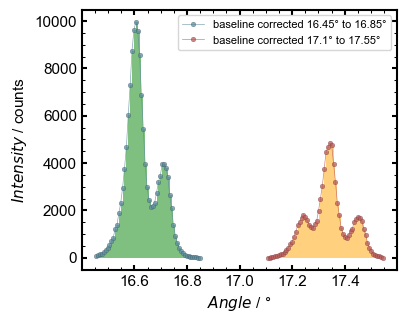

The ratio of the peak areas (I006 + I102) / I101 is: 0.5731424997795339


In [10]:
# smoothness of the baseline (arPLS): the ratio changes by less than 2 % between 1e4 and 1e6
lam = 1e4

fig = plt.figure()

### area of the (101) reflection
area_101 = Determine_Peak_Area_Summed(raw_data[0], 'Angle', 'Intensity', 16.45, 16.85, lam, 'green')

### area of the (006) and (102) reflections
area_006_102 = Determine_Peak_Area_Summed(raw_data[0], 'Angle', 'Intensity', 17.10, 17.55, lam, 'orange')

plt.xlabel(r'$Angle$ / °')
plt.ylabel(r'$Intensity$ / counts')
plt.legend()
plt.savefig(images_outdir + 'XRD_LNO13_peak_areas.png')
plt.show()

ratio = area_006_102 / area_101
print('The ratio of the peak areas (I006 + I102) / I101 is: %s' %(ratio))

## Fit of two Gaussian functions

The (101) reflection is split into the K<sub>α1</sub> and the K<sub>α2</sub> line. Both lines are fitted with one Gaussian function each (lmfit, Nelder-Mead). The amplitude `amp` is the area of the Gaussian function.

Maximum number of iterations exceeded
[[Fit Statistics]]
    # fitting method   = Nelder-Mead
    # function evals   = 500
    # data points      = 56
    # variables        = 6
    chi-square         = 8492668.56
    reduced chi-square = 169853.371
    Akaike info crit   = 680.044280
    Bayesian info crit = 692.196390
[[Variables]]
    amp1:    721.007958 +/- 12.9993284 (1.80%) (init = 400)
    sigma1:  0.03035173 +/- 5.7066e-04 (1.88%) (init = 0.02)
    cen1:    16.6000000 +/- 6.8527e-04 (0.00%) (init = 16.6)
    amp2:    278.151259 +/- 12.0472927 (4.33%) (init = 200)
    sigma2:  0.02838929 +/- 0.00130555 (4.60%) (init = 0.02)
    cen2:    16.7107170 +/- 3.9215e-04 (0.00%) (init = 16.71)


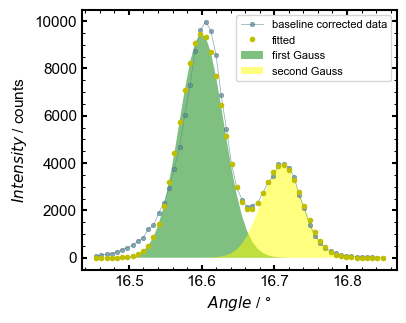

Area ratio K_alpha2 / K_alpha1: 0.3857811224656568


In [11]:
### Start values for the fit and their limits
FitParameters = Parameters()
FitParameters.add('amp1', value=400, max=1000, min=100)
FitParameters.add('sigma1', value=0.02, max=0.05, min=0.005)
FitParameters.add('cen1', value=16.60, max=16.65, min=16.55)

FitParameters.add('amp2', value=200, max=600, min=50)
FitParameters.add('sigma2', value=0.02, max=0.05, min=0.005)
FitParameters.add('cen2', value=16.71, max=16.76, min=16.66)

fig = plt.figure()

result_fit = Fit_Two_Gauss_Peaks(raw_data[0], 'Angle', 'Intensity', 16.45, 16.85, lam, FitParameters)

plt.xlabel(r'$Angle$ / °')
plt.ylabel(r'$Intensity$ / counts')
plt.legend()
plt.savefig(images_outdir + 'XRD_LNO13_101_Gauss_fit.png')
plt.show()

print('Area ratio K_alpha2 / K_alpha1: %s' %(result_fit.params['amp2'].value / result_fit.params['amp1'].value))